In [1]:
# === Ô GHI LOG ===
import logging, sys, datetime, warnings
from pathlib import Path
TEN_NOTEBOOK = "01_E0.6_tach_lop_pca_tsne_Han"
NGUOI_CHAY   = "Han"

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # thư mục gốc repo
thu_muc_log = ROOT / "logs" / "eda_log"   # log các notebook EDA để riêng
thu_muc_log.mkdir(parents=True, exist_ok=True)
file_log = thu_muc_log / f"{datetime.datetime.now():%Y-%m-%d_%H%M}_{TEN_NOTEBOOK}.log"
tep_log = open(file_log, "a", encoding="utf-8", buffering=1)

if hasattr(sys.stdout, "echo"):                  # chạy trong Jupyter / VS Code: nhờ kernel chép thêm ra file, không thay sys.stdout
    sys.stdout.echo = tep_log
    sys.stderr.echo = tep_log
else:                                            # chạy bằng python thường
    class GhiCaHai:
        def __init__(self, man_hinh, tep): self.man_hinh, self.tep = man_hinh, tep
        def write(self, s): self.man_hinh.write(s); self.tep.write(s); return len(s)
        def flush(self): self.man_hinh.flush(); self.tep.flush()
        def __getattr__(self, ten): return getattr(self.man_hinh, ten)
    sys.stdout = GhiCaHai(sys.__stdout__, tep_log)

logging.basicConfig(stream=sys.stdout, level=logging.INFO, force=True,
                    format="%(asctime)s | %(levelname)s | %(message)s", datefmt="%Y-%m-%d %H:%M:%S")
logging.captureWarnings(True)
log = logging.getLogger(TEN_NOTEBOOK)
log.info(f"Bắt đầu chạy {TEN_NOTEBOOK} – người chạy: {NGUOI_CHAY} – file log: {file_log}")

2026-11-14 18:13:40 | INFO | Bắt đầu chạy 01_E0.6_tach_lop_pca_tsne_Han – người chạy: Han – file log: /Users/caongochan/Documents/Challenge_2_Music_Genre_Classification/logs/2026-11-14_1813_01_E0.6_tach_lop_pca_tsne_Han.log


# E0.6 – Các thể loại có tách được nhau không? (C2 – Music Genre)

| | |
|---|---|
| **Tác giả** | Cao Ngọc Hân – Nhóm 11 |
| **Ngày tạo** | 14/11/2026 |
| **Thí nghiệm** | E0.6 – Các thể loại có tách được nhau không? |
| **Câu hỏi nghiên cứu** | RQ0: Đặc trưng âm thanh nào phân biệt các thể loại tốt nhất? · RQ4: thể loại nào hay bị nhầm |
| **Đọc vào** | `data/raw/train.csv` |
| **Ghi ra** | `figures/eda/c2_E0.6_tach_lop.png`, `c2_E0.6_silhouette.csv`, `c2_E0.6_tom_tat.txt` |

**Lịch sử sửa**

| Ngày | Người | Nội dung |
|---|---|---|
| 08/11/2026 | Hân | Viết trong `01_eda_Han.ipynb` (E0.1–E0.6 chung một notebook) |
| 14/11/2026 | Hân | Tách thành notebook riêng; thêm ô ghi log ra `logs/` |

Notebook chỉ dùng thống kê và mô hình đơn giản (hồi quy logistic). Mô hình mạnh là việc của Nhung.

**Cách chạy:** chạy các notebook EDA theo thứ tự E0.1 → E0.6 (Run All). File log nằm ở `logs/eda_log/`. Bản gộp đọc từ trên xuống: `00_EDA_tong_hop_C2_Han.ipynb`.

In [2]:
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_classif, f_classif
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", font_scale=1.0)

SEED = 42
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # notebook nằm ở notebooks/eda/
DATA = ROOT / "data" / "raw"
FIG = ROOT / "figures" / "eda"
FIG.mkdir(parents=True, exist_ok=True)

# W&B: USE_WANDB là công tắc chung; LOG chọn thí nghiệm nào được log ở lần chạy này.
# Các run W&B của E0.1–E0.6 đã log ngày 08/11 (từ 01_eda_Han.ipynb).
# Để USE_WANDB = False khi chạy lại để không tạo run trùng; bật True nếu cần log run mới.
USE_WANDB = False
LOG = {"E0.6": True}
WANDB_ENTITY = "sgu-mayhoc-nhom11"
WANDB_PROJECT = "challenge-2-music-genre-classification"
log.info(f"ROOT: {ROOT}")

2026-11-14 18:13:41 | INFO | ROOT: /Users/caongochan/Documents/Challenge_2_Music_Genre_Classification


In [3]:
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
TARGET, ID = "Class", "Id"
TEXT_COLS = ["Artist Name", "Track Name"]
print("train:", train.shape, "| test:", test.shape)
train.head()

train: (14396, 18) | test: (3600, 17)


,Id,Artist Name,Track Name,Popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_in min/ms,time_signature,Class
0,1,Marina Maximilian,Not Afraid,37.0,0.334,0.536,9.0,-6.649,0,0.0381,0.378000,NaN,0.106,0.235,152.429,204947.0,4,9
1,2,The Black Keys,Howlin' for You,67.0,0.725,0.747,11.0,-5.545,1,0.0876,0.027200,0.0468,0.104,0.380,132.921,191956.0,4,6
2,3,Royal & the Serpent,phuck u,NaN,0.584,0.804,7.0,-6.094,1,0.0619,0.000968,0.6350,0.284,0.635,159.953,161037.0,4,10
3,4,Detroit Blues Band,Missing You,12.0,0.515,0.308,NaN,-14.711,1,0.0312,0.907000,0.0213,0.300,0.501,172.472,298093.0,3,2
4,5,Coast Contra,My Lady,48.0,0.565,0.777,6.0,-5.096,0,0.2490,0.183000,NaN,0.211,0.619,88.311,254145.0,4,5


In [4]:
# Chuẩn bị chung (lấy lại từ E0.1, E0.2): tách đặc trưng; đổi thời lượng về phút và điền thiếu bằng trung vị
# (chỉ để phân tích, không phải pipeline mô hình); 5 fold phân tầng và hồi quy logistic dùng chung
X = train.drop(columns=[ID, TARGET])
y = train[TARGET]
num_cols = [c for c in X.columns if c not in TEXT_COLS]
Xa = X[num_cols].copy()
Xa["duration_in min/ms"] = np.where(Xa["duration_in min/ms"] < 30, Xa["duration_in min/ms"],
                                    Xa["duration_in min/ms"] / 60000)
Xa = Xa.rename(columns={"duration_in min/ms": "duration_min"})
num_cols = list(Xa.columns)
Xa = Xa.fillna(Xa.median())

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
def logit():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
baseline_f1 = 1 / y.nunique()
log.info(f"{len(num_cols)} đặc trưng số, {y.nunique()} thể loại, macro-F1 ngẫu nhiên ≈ {baseline_f1:.3f}")

2026-11-14 18:13:41 | INFO | 14 đặc trưng số, 11 thể loại, macro-F1 ngẫu nhiên ≈ 0.091


## E0.6 – Các thể loại có tách được nhau không?

Chiếu 14 đặc trưng (đã chuẩn hóa) xuống 2 chiều bằng **PCA** (giữ cấu trúc tuyến tính) và **t-SNE** (giữ lân cận cục bộ, chạy trên 4000 bài lấy mẫu phân tầng), tô màu theo thể loại. Đo thêm **silhouette** theo nhãn thể loại: gần 1 là các thể loại tách rời, gần 0 hoặc âm là chồng lấn.

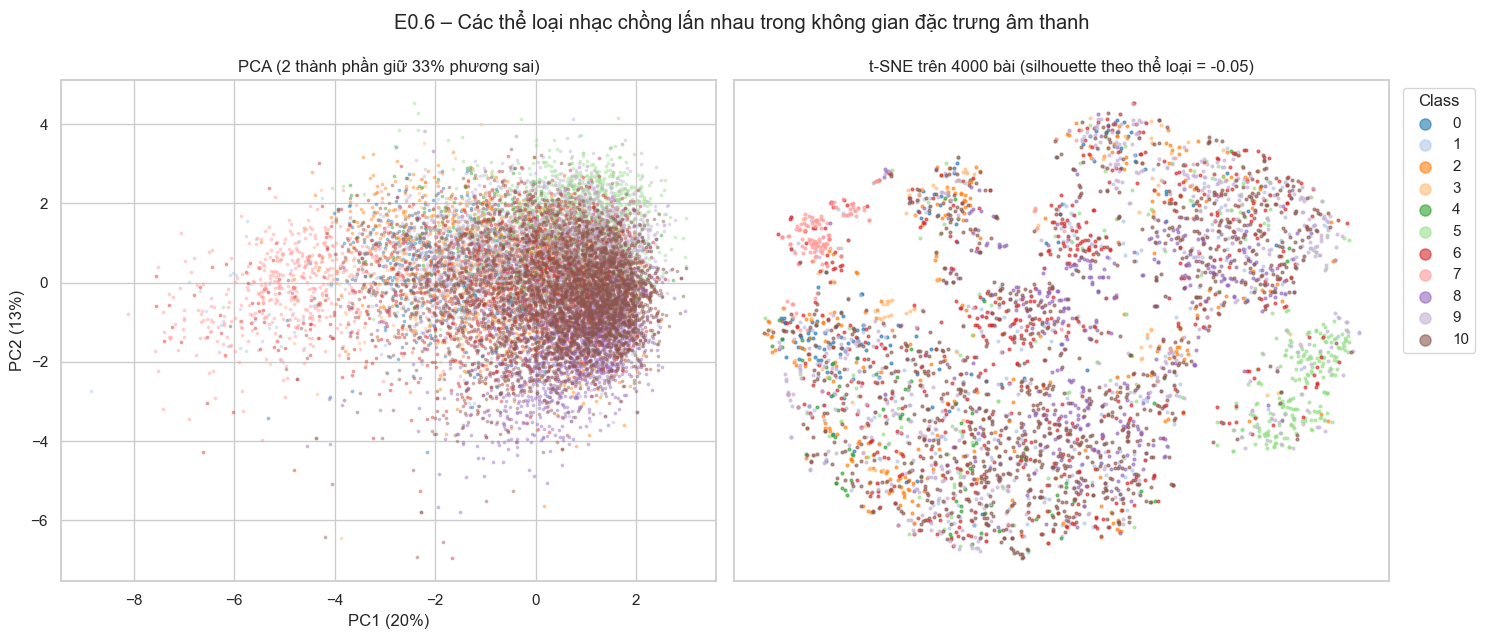

Silhouette toàn bộ: -0.049. PCA 2 chiều giữ 33% phương sai.


,so_bai,silhouette_1_vs_con_lai
7,461,0.276
5,1157,0.104
3,322,0.075
8,1483,0.034
2,1018,0.022
6,2069,0.001
0,500,-0.000
10,3959,-0.016
9,2019,-0.019
1,1098,-0.035


In [5]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.model_selection import train_test_split

Z = StandardScaler().fit_transform(Xa)
pca = PCA(n_components=2, random_state=SEED).fit(Z)
P = pca.transform(Z)
idx_s, _ = train_test_split(np.arange(len(y)), train_size=4000, stratify=y, random_state=SEED)
T = TSNE(n_components=2, perplexity=40, init="pca", random_state=SEED).fit_transform(Z[idx_s])
sil_all = silhouette_score(Z[idx_s], y.iloc[idx_s])
sil_per = pd.Series({k: silhouette_score(Z[idx_s], (y.iloc[idx_s] == k).astype(int)) for k in sorted(y.unique())})
pca_var = pca.explained_variance_ratio_

palette = sns.color_palette("tab20", n_colors=y.nunique())
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for k, col in zip(sorted(y.unique()), palette):
    m = (y == k).to_numpy()
    axes[0].scatter(P[m, 0], P[m, 1], s=3, alpha=0.35, color=col, label=str(k))
    ms = (y.iloc[idx_s] == k).to_numpy()
    axes[1].scatter(T[ms, 0], T[ms, 1], s=4, alpha=0.6, color=col, label=str(k))
axes[0].set_title(f"PCA (2 thành phần giữ {pca_var.sum():.0%} phương sai)")
axes[0].set_xlabel(f"PC1 ({pca_var[0]:.0%})"); axes[0].set_ylabel(f"PC2 ({pca_var[1]:.0%})")
axes[1].set_title(f"t-SNE trên 4000 bài (silhouette theo thể loại = {sil_all:.2f})")
axes[1].set_xticks([]); axes[1].set_yticks([])
axes[1].legend(title="Class", markerscale=4, bbox_to_anchor=(1.01, 1), loc="upper left")
fig.suptitle("E0.6 – Các thể loại nhạc chồng lấn nhau trong không gian đặc trưng âm thanh")
plt.tight_layout(); plt.savefig(FIG / "c2_E0.6_tach_lop.png", dpi=150); plt.show()

e06_tbl = pd.DataFrame({"so_bai": y.value_counts().sort_index(), "silhouette_1_vs_con_lai": sil_per.round(3)})
e06_tbl.to_csv(FIG / "c2_E0.6_silhouette.csv")
print(f"Silhouette toàn bộ: {sil_all:.3f}. PCA 2 chiều giữ {pca_var.sum():.0%} phương sai.")
e06_tbl.sort_values("silhouette_1_vs_con_lai", ascending=False)

## Tóm tắt E0.6

In [6]:
summary = f"""E0.6 (C2): silhouette theo thể loại = {sil_all:.2f} (gần 0 là chồng lấn); PCA 2 chiều giữ {pca_var.sum():.0%} phương sai.
  Thể loại tách rõ nhất: {', '.join(str(k) for k in sil_per.sort_values(ascending=False).index[:2])}; chồng lấn nhiều nhất: {', '.join(str(k) for k in sil_per.sort_values().index[:2])}."""
log.info("Tóm tắt E0.6:\n" + summary)
(FIG / "c2_E0.6_tom_tat.txt").write_text(summary, encoding="utf-8")

2026-11-14 18:13:53 | INFO | Tóm tắt E0.6:
E0.6 (C2): silhouette theo thể loại = -0.05 (gần 0 là chồng lấn); PCA 2 chiều giữ 33% phương sai.
  Thể loại tách rõ nhất: 7, 5; chồng lấn nhiều nhất: 4, 1.


156

## Log lên W&B (minh chứng)

In [7]:
if USE_WANDB:
    import wandb
    def log_run(exp, name, metrics, tables, images, config=None):
        if not LOG.get(exp):
            print(f"Bỏ qua {exp} (LOG = False)"); return
        run = wandb.init(entity=WANDB_ENTITY, project=WANDB_PROJECT, name=name,
                         tags=[exp, "Han", "EDA"], config={"seed": SEED, **(config or {})})
        run.log({**metrics,
                 **{k: wandb.Table(dataframe=v) for k, v in tables.items()},
                 **{f.removesuffix(".png"): wandb.Image(str(FIG / f)) for f in images}})
        run.finish()

    log_run("E0.6", "c2-E0.6-Han-tach-lop-pca-tsne",
            {"silhouette": float(sil_all), "pca_2d_variance": float(pca_var.sum())},
            {"silhouette_tung_lop": e06_tbl.reset_index(names="Class")}, ["c2_E0.6_tach_lop.png"],
            {"tsne_sample": 4000, "perplexity": 40})

## Nhật ký

- 08/11/2026 – Viết E0.6 lần đầu trong notebook `01_eda_Han.ipynb`. Commit `fa7d8ad`.
- 14/11/2026 – Tách E0.6 ra thành notebook riêng `01_E0.6_tach_lop_pca_tsne_Han.ipynb`, thêm ô ghi log. Commit `eaa2795`.